# Why do clinical trials stop early?

A clinical trial that is **terminated** stops before reaching its planned end. Patients have been exposed to an experimental treatment, money has been spent, and the scientific question often goes unanswered.

**Data:** every interventional **phase 2 or phase 3** trial registered on [ClinicalTrials.gov](https://clinicaltrials.gov/) that **started between 2008 and 2019** and has since either **completed** or been **terminated**: 46,911 trials. Trials that started after 2019 are left out because many are still running, and including them would over-represent short trials.

**Questions**
1. How common is early termination?
2. What reasons do sponsors give?
3. Which kinds of trials stop more often: by phase, sponsor, design and disease area?
4. How has this changed over time?

> Run `python src/download_data.py` and `python src/build_dataset.py` first.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import style
style.apply()

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120)

trials = pd.read_parquet(ROOT / "data" / "processed" / "trials.parquet")
REASONS = [c for c in trials if c.startswith("reason_")]
AREAS = [c for c in trials if c.startswith("area_")]
OVERALL = trials["terminated"].mean()
print(f"{len(trials):,} trials, {trials['terminated'].sum():,} terminated ({OVERALL:.1%})")

46,911 trials, 7,707 terminated (16.4%)


In [2]:
def rate_chart(series_rate, series_n, title, name, xlabel="Share of trials terminated (%)", sort=True, figsize=(8, 3.5)):
    """Horizontal bars of termination rate per group, with the overall rate as a reference line."""
    s = series_rate.sort_values() if sort else series_rate
    n = series_n.reindex(s.index)
    fig, ax = plt.subplots(figsize=figsize)
    colors = [style.ORANGE if v > OVERALL else style.BLUE for v in s]
    ax.barh(s.index, s * 100, color=colors, height=0.6)
    for i, (v, k) in enumerate(zip(s, n)):
        ax.text(v * 100 + 0.3, i, f"{v:.0%}  (n={k:,})", va="center", fontsize=8.5, color=style.TEXT_2)
    ax.axvline(OVERALL * 100, color=style.TEXT_2, lw=1, ls="--")
    ax.text(OVERALL * 100 + 0.3, len(s) - 0.4, f"all trials {OVERALL:.0%}", fontsize=8.5, color=style.TEXT_2)
    ax.set(xlim=(0, max(s) * 100 * 1.35), xlabel=xlabel, title=title)
    ax.grid(axis="y", visible=False)
    save_fig(name)
    plt.show()

## 1. How common is early termination?

About **1 in 6** phase 2/3 trials (16.4%) is terminated early. That is the baseline for everything that follows: bars above the dashed line in the charts below are groups that stop more often than average.

## 2. What reasons do sponsors give?

Terminated trials must state a reason in a free-text field ("why stopped"). We grouped the texts into categories with keyword rules (see `build_dataset.py`). The rules ignore phrases such as *"not related to safety"*, and a trial can fall into more than one category.

Terminated trials with a written reason: 89%


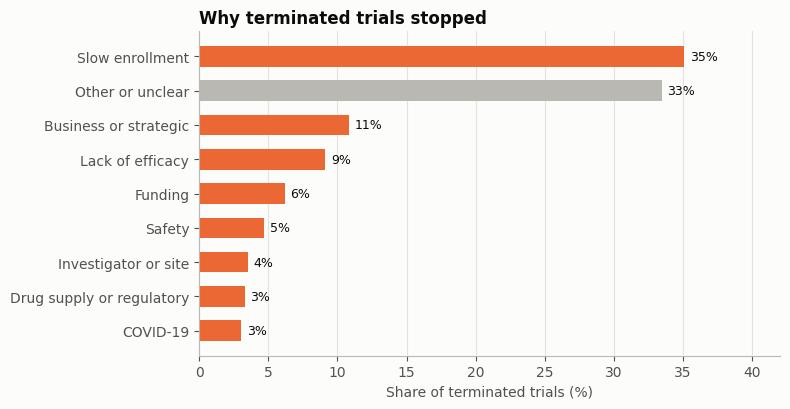

In [3]:
terminated = trials[trials["terminated"] == 1]
reasons = terminated[REASONS].mean().rename(lambda c: c.replace("reason_", "")).sort_values()
print(f"Terminated trials with a written reason: {terminated['why_stopped'].notna().mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [style.NEUTRAL if r == "Other or unclear" else style.ORANGE for r in reasons.index]
ax.barh(reasons.index, reasons * 100, color=colors, height=0.6)
for i, v in enumerate(reasons):
    ax.text(v * 100 + 0.4, i, f"{v:.0%}", va="center", fontsize=9)
ax.set(xlim=(0, 42), xlabel="Share of terminated trials (%)", title="Why terminated trials stopped")
ax.grid(axis="y", visible=False)
save_fig("01_reasons")
plt.show()

In [4]:
examples = {r: terminated.loc[terminated[r] == 1, "why_stopped"].sample(3, random_state=4).tolist() for r in REASONS[:6]}
for r, texts in examples.items():
    print(f"\n{r.replace('reason_', '')}:")
    for t in texts:
        print("  •", t[:140])


Slow enrollment:
  • Due to the enrollment was slow and exceeded the expected enrollment time
  • Enrollment was delayed and the number of eligible patients significantly declined with the use of neoadjuvant or adjuvant ICIs and TKIs ther
  • Study Investigator/Sponsor decided to end enrollment earlier.

Business or strategic:
  • company decision
  • AVROBIO has deprioritized its Fabry disease program
  • The study was terminated prior to the planned final on-treatment efficacy assessments due to commercial availability of tocilizumab in Russi

Funding:
  • lack of funding
  • Komen Foundation Funding Terminated
  • Funding expired

Lack of efficacy:
  • Lack of Efficacy
  • Lack of efficacy
  • Study termination due to insufficient efficacy.

Safety:
  • The study used a two-stage design. After stage one, the study was terminated due to excess toxicity.
  • Excess toxicity was identified intraoperatively
  • Study team felt toxicity of study regimen outweighed potential benefit.

In

**Most trials do not stop because the drug failed.**
- The single biggest reason is **slow enrollment**, cited in about **35%** of terminations: not enough patients could be recruited.
- Next come **business or strategic** decisions (11%) and **funding** (6%).
- Scientific reasons are less common: **lack of efficacy** (9%) and **safety** (5%).

So most early stops are **operational or commercial**, not medical. That matters: those reasons are, at least in principle, things that better planning could prevent.

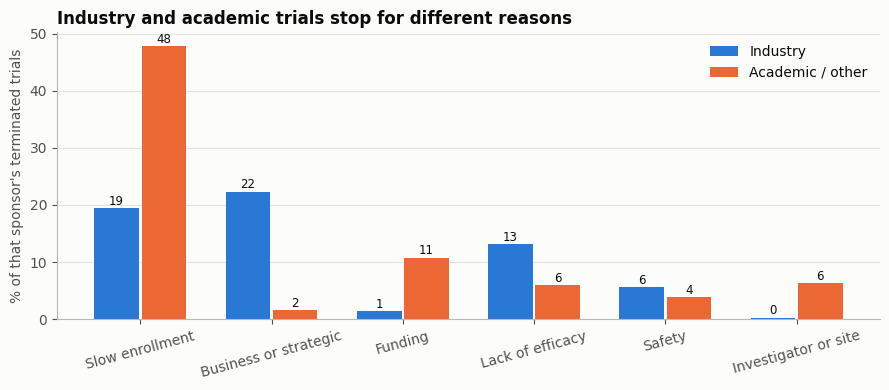

,Slow enrollment,Business or strategic,Funding,Lack of efficacy,Safety,Investigator or site
sponsor,,,,,,
Industry,0.195,0.223,0.014,0.131,0.055,0.003
Academic / other,0.478,0.016,0.107,0.059,0.039,0.063


In [5]:
by_sponsor = (terminated.groupby("sponsor")[REASONS].mean()
              .rename(columns=lambda c: c.replace("reason_", "")).loc[["Industry", "Academic / other"]])
show = ["Slow enrollment", "Business or strategic", "Funding", "Lack of efficacy", "Safety", "Investigator or site"]
x = np.arange(len(show))
fig, ax = plt.subplots(figsize=(9, 4))
for i, (sponsor, color) in enumerate([("Industry", style.BLUE), ("Academic / other", style.ORANGE)]):
    vals = by_sponsor.loc[sponsor, show] * 100
    ax.bar(x + (i - 0.5) * 0.36, vals, width=0.34, color=color, label=sponsor)
    for xi, v in zip(x, vals):
        ax.text(xi + (i - 0.5) * 0.36, v + 0.6, f"{v:.0f}", ha="center", fontsize=8.5)
ax.set_xticks(x, show, rotation=15)
ax.set(ylabel="% of that sponsor's terminated trials", title="Industry and academic trials stop for different reasons")
ax.legend()
ax.grid(axis="x", visible=False)
save_fig("02_reasons_by_sponsor")
plt.show()
by_sponsor[show].round(3)

- **Industry** trials are far more often stopped for **business or strategic** reasons. A company may drop a drug from its portfolio after a merger, a competitor's success, or a change of priorities.
- **Academic** trials are more often stopped for **slow enrollment** (nearly half of them), **funding** and **investigator** reasons (for example, the lead doctor moving to another hospital). They depend on smaller budgets and on individual researchers.
- **Lack of efficacy** is cited about twice as often by industry. Company trials more often have pre-planned interim analyses that can stop a trial for futility.

## 3. Which trials stop more often?

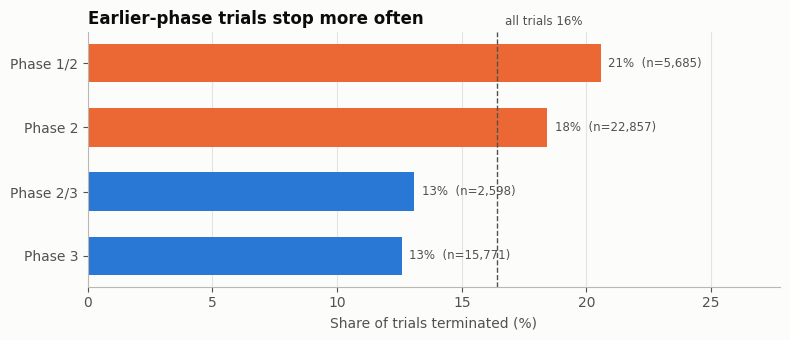

In [6]:
g = trials.groupby("phase")["terminated"]
rate_chart(g.mean(), g.size(), "Earlier-phase trials stop more often", "03_by_phase")

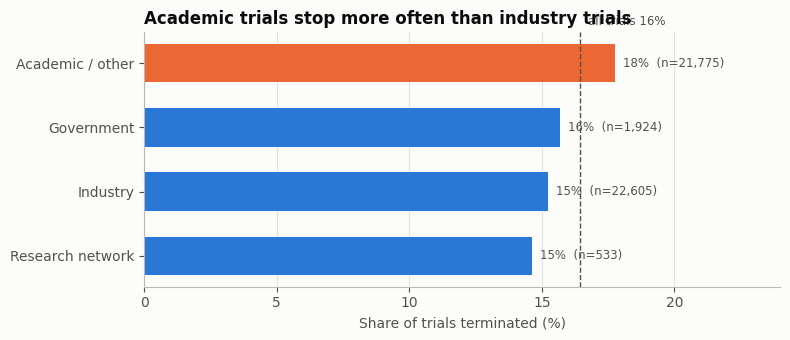

In [7]:
g = trials[trials["sponsor"] != "Other"].groupby("sponsor")["terminated"]
rate_chart(g.mean(), g.size(), "Academic trials stop more often than industry trials", "04_by_sponsor")

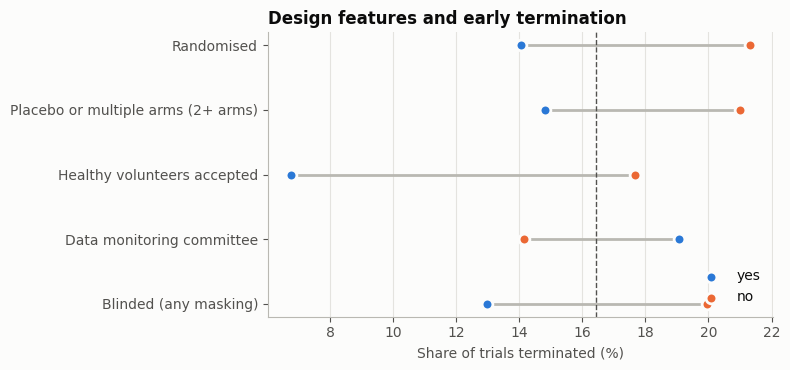

group,yes,no
feature,,
Blinded (any masking),13.0,20.0
Data monitoring committee,19.1,14.2
Healthy volunteers accepted,6.8,17.7
Placebo or multiple arms (2+ arms),14.8,21.0
Randomised,14.1,21.3


In [8]:
design = pd.DataFrame({
    "Randomised": trials["allocation"].eq("RANDOMIZED"),
    "Blinded (any masking)": ~trials["masking"].isin(["NONE", "UNKNOWN"]),
    "Placebo or multiple arms (2+ arms)": trials["n_arms"] >= 2,
    "Data monitoring committee": trials["has_dmc"].eq("Yes"),
    "Healthy volunteers accepted": trials["healthy_volunteers"].eq(1),
})
rows = []
for feature, flag in design.items():
    for value, label in [(True, "yes"), (False, "no")]:
        rows.append({"feature": feature, "group": label, "rate": trials.loc[flag == value, "terminated"].mean(),
                     "n": (flag == value).sum()})
design_rates = pd.DataFrame(rows).pivot(index="feature", columns="group", values="rate")[["yes", "no"]]

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(design_rates))
ax.hlines(y, design_rates["yes"] * 100, design_rates["no"] * 100, color=style.NEUTRAL, lw=2)
ax.scatter(design_rates["yes"] * 100, y, color=style.BLUE, s=60, zorder=3, label="yes", edgecolor=style.SURFACE, lw=2)
ax.scatter(design_rates["no"] * 100, y, color=style.ORANGE, s=60, zorder=3, label="no", edgecolor=style.SURFACE, lw=2)
ax.set_yticks(y, design_rates.index)
ax.axvline(OVERALL * 100, color=style.TEXT_2, lw=1, ls="--")
ax.set(xlabel="Share of trials terminated (%)", title="Design features and early termination")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig("05_by_design")
plt.show()
(design_rates * 100).round(1)

- **Randomised** and **blinded** trials stop less often (about 14% and 13%) than single-arm, open-label ones (about 21% and 20%). Rigorous designs tend to come from well-planned, well-funded programmes. Open-label single-arm studies are often small, exploratory or academic.
- Trials with a **data monitoring committee** stop *more* often (19% vs 14%). This doesn't make DMCs harmful. Their job is to **recommend stopping** when interim data show harm or futility, and they are set up for larger, riskier trials.
- Trials that accept **healthy volunteers** (for example vaccines and prevention) rarely stop.

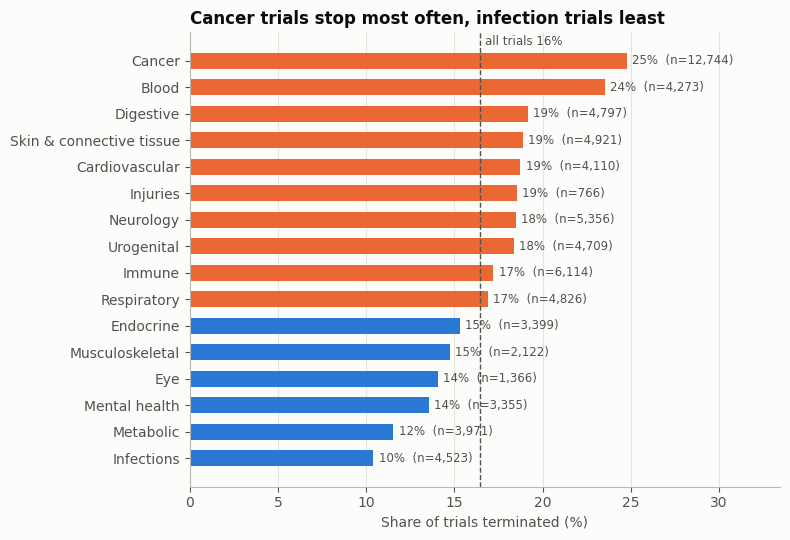

In [9]:
area_rate = pd.Series({a.replace("area_", ""): trials.loc[trials[a] == 1, "terminated"].mean() for a in AREAS})
area_n = pd.Series({a.replace("area_", ""): int(trials[a].sum()) for a in AREAS})
rate_chart(area_rate, area_n, "Cancer trials stop most often, infection trials least", "06_by_area", figsize=(8, 5.5))

Disease areas are the top-level MeSH categories of each trial's conditions. A trial can belong to several areas (for example, lung cancer is both *Cancer* and *Respiratory*).
- **Cancer** (25%) and **blood** disorders (24%) have the highest termination rates. Oncology trials often recruit narrowly defined patient groups, compete for the same patients, and have demanding protocols.
- **Infections** (10%) and **metabolic** diseases (12%) have the lowest. Many are vaccine or diabetes trials with large, easier-to-find populations.

In [10]:
cancer = terminated[terminated["area_Cancer"] == 1]
other = terminated[terminated["area_Cancer"] == 0]
cmp = pd.DataFrame({"Cancer": cancer[REASONS].mean(), "Other areas": other[REASONS].mean()})
cmp.index = cmp.index.str.replace("reason_", "")
(cmp * 100).round(1).sort_values("Cancer", ascending=False)

,Cancer,Other areas
Slow enrollment,41.2,30.8
Other or unclear,29.4,36.3
Business or strategic,10.4,11.2
Lack of efficacy,7.9,10.0
Funding,6.7,5.9
Safety,4.9,4.6
Investigator or site,4.1,3.1
Drug supply or regulatory,3.5,3.1
COVID-19,0.9,4.5


Within cancer, **slow enrollment** is an even bigger share of terminations than elsewhere. The difficulty of finding eligible patients is the main driver of oncology's high termination rate.

## 4. Changes over time

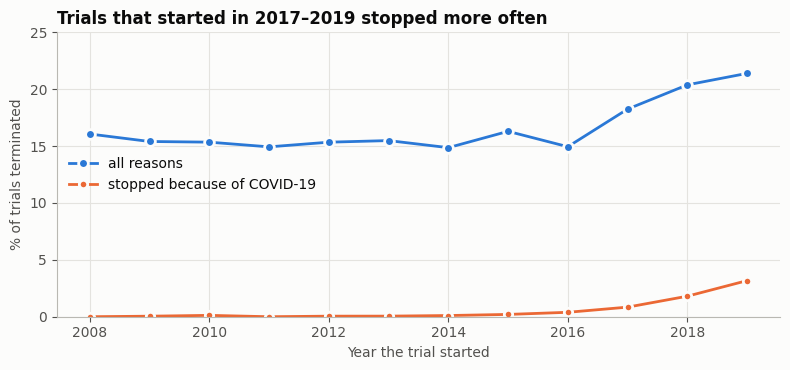

start_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
mean,0.161,0.154,0.153,0.149,0.153,0.155,0.149,0.163,0.149,0.183,0.204,0.214
size,4383.000,4317.000,4190.000,4239.000,4067.000,3875.000,3815.000,3958.000,3600.000,3676.000,3547.000,3244.000
covid,0.000,0.000,0.001,0.000,0.000,0.001,0.001,0.002,0.004,0.008,0.018,0.032


In [11]:
by_year = trials.groupby("start_year")["terminated"].agg(["mean", "size"])
covid = trials.groupby("start_year")["reason_COVID-19"].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by_year.index, by_year["mean"] * 100, marker="o", ms=7, color=style.BLUE, label="all reasons",
        markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.plot(covid.index, covid * 100, marker="o", ms=6, color=style.ORANGE, label="stopped because of COVID-19",
        markeredgecolor=style.SURFACE, markeredgewidth=2)
ax.set(ylim=(0, 25), xlabel="Year the trial started", ylabel="% of trials terminated", title="Trials that started in 2017–2019 stopped more often")
ax.legend(loc="center left")
save_fig("07_by_year")
plt.show()
by_year.assign(covid=covid).round(3).T

Termination was stable at about 15% for trials started between 2008 and 2016, then rose to about 21% for trials started in 2019.
Part of that rise is **COVID-19**: trials that were still recruiting in 2020 were hit by the pandemic, and about 3% of all trials started in 2019 cite it explicitly.
The rest may reflect a **reporting effect**: recent trials have had less time to finish, so the slow ones that eventually *complete* are still missing from the data.

## Summary
- **1 in 6** phase 2/3 trials stops early.
- The most common reasons are **operational and commercial**: slow enrollment (35%), business decisions (11%) and funding (6%). Efficacy (9%) and safety (5%) are less common.
- Trials more likely to stop are **earlier-phase**, **academic**, **open-label**, **non-randomised**, and in **cancer** or **blood** disorders.
- Notebook 02 asks whether these features can **predict** termination before a trial starts.